# Medical Cost Prediction using Machine Learning
**IBM SkillsBuild Data Analytics with AI – Academic Internship (BharatCares × AICTE)**

**Dataset:** [Medical Cost Personal Datasets – Kaggle](https://www.kaggle.com/datasets/mirichoi0218/insurance)

**Goal:** Predict the individual medical insurance charges billed by a health insurer from a person's age, sex, BMI, number of children, smoking status and region, and identify which factors drive cost the most.

**Workflow:** Load data → Clean → Explore (EDA) → Feature engineering → Train/test split → Train 4 models → Compare → Tune best model → Interpret → Save model

## 1. Import Libraries

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)   # all charts are saved here
print("Libraries loaded successfully")

Libraries loaded successfully


## 2. Load the Dataset
Download `insurance.csv` from the Kaggle link above and place it in the same folder as this notebook.

In [2]:
df = pd.read_csv("insurance.csv")
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


**Column description**

| Column | Meaning |
|---|---|
| age | Age of primary beneficiary |
| sex | Gender of insurance contractor (female / male) |
| bmi | Body Mass Index (kg/m²) |
| children | Number of children / dependents covered |
| smoker | Whether the person smokes (yes / no) |
| region | Residential area in the US (northeast, northwest, southeast, southwest) |
| charges | **Target** – individual medical costs billed by health insurance (USD) |

## 3. Data Cleaning & Quality Checks

In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1


In [5]:
# Remove the duplicate record(s)
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1337, 7)


In [6]:
df.describe().round(2)

,age,bmi,children,charges
count,1337.00,1337.00,1337.00,1337.00
mean,39.22,30.66,1.10,13279.12
std,14.04,6.10,1.21,12110.36
min,18.00,15.96,0.00,1121.87
25%,27.00,26.29,0.00,4746.34
50%,39.00,30.40,1.00,9386.16
75%,51.00,34.70,2.00,16657.72
max,64.00,53.13,5.00,63770.43


## 4. Exploratory Data Analysis (EDA)

### 4.1 Distribution of the target (charges)
Charges are right-skewed – most people have low bills but a few have very high ones.

Skewness of charges: 1.52


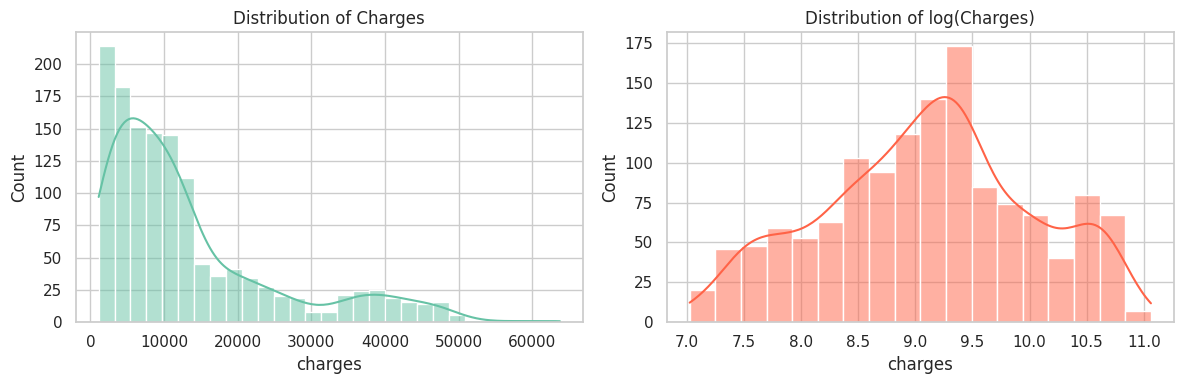

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["charges"], kde=True, ax=ax[0])
ax[0].set_title("Distribution of Charges")
sns.histplot(np.log1p(df["charges"]), kde=True, ax=ax[1], color="tomato")
ax[1].set_title("Distribution of log(Charges)")
plt.tight_layout()
plt.savefig("figures/01_charges_distribution.png", dpi=120)
plt.show()
print("Skewness of charges:", round(df["charges"].skew(), 2))

### 4.2 Categorical features vs charges

smoker
no      8441.0
yes    32050.0
Name: charges, dtype: float64


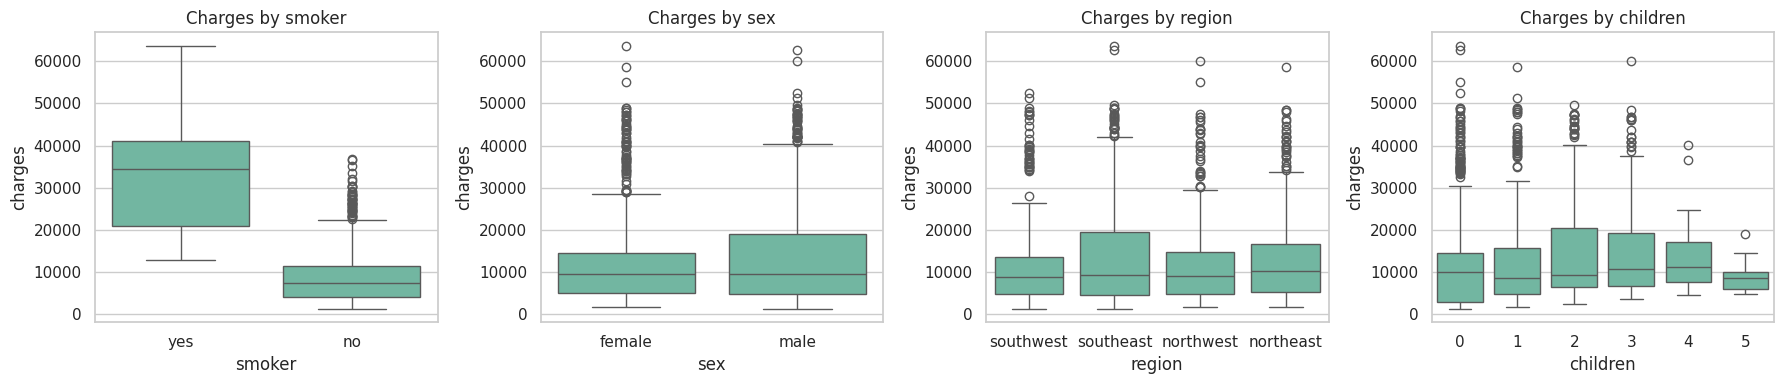

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, ["smoker", "sex", "region", "children"]):
    sns.boxplot(data=df, x=col, y="charges", ax=ax)
    ax.set_title(f"Charges by {col}")
plt.tight_layout()
plt.savefig("figures/02_categorical_vs_charges.png", dpi=120)
plt.show()

print(df.groupby("smoker")["charges"].mean().round(0))

### 4.3 Age and BMI vs charges (coloured by smoking status)

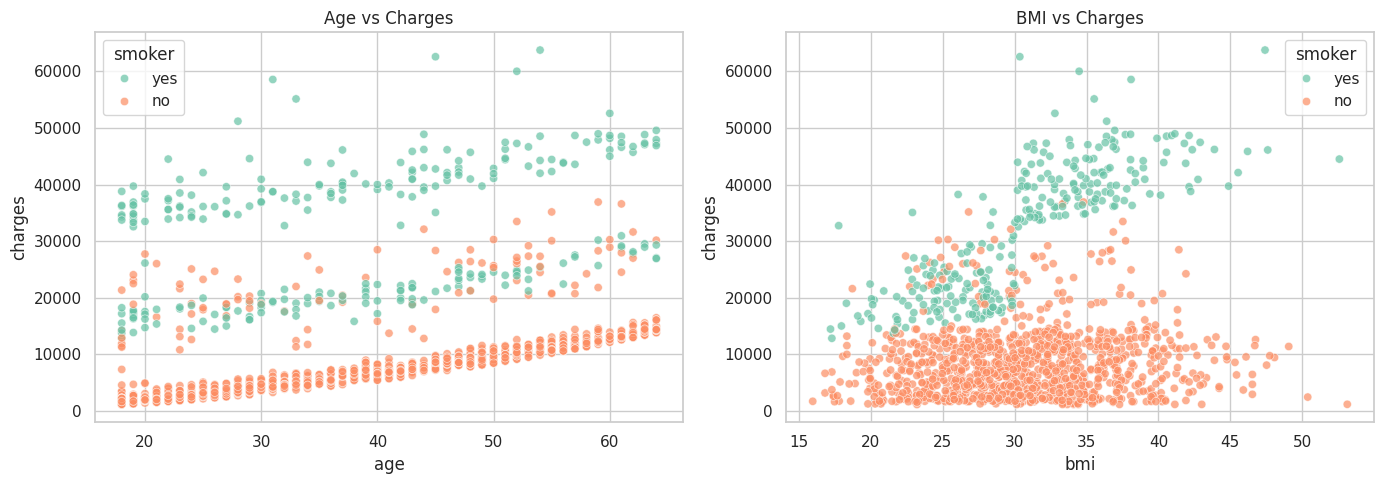

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=0.7, ax=ax[0])
ax[0].set_title("Age vs Charges")
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.7, ax=ax[1])
ax[1].set_title("BMI vs Charges")
plt.tight_layout()
plt.savefig("figures/03_age_bmi_vs_charges.png", dpi=120)
plt.show()

### 4.4 Correlation heatmap

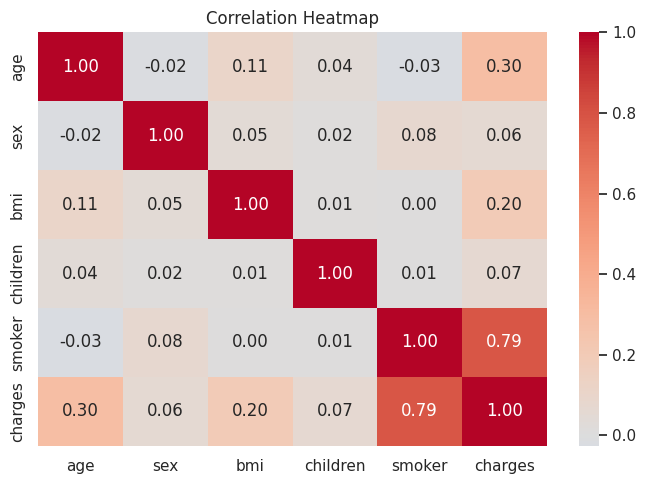

In [10]:
corr_df = df.copy()
corr_df["smoker"] = (corr_df["smoker"] == "yes").astype(int)
corr_df["sex"] = (corr_df["sex"] == "male").astype(int)
plt.figure(figsize=(7, 5))
sns.heatmap(corr_df.drop(columns="region").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.savefig("figures/04_correlation_heatmap.png", dpi=120)
plt.show()

**Key EDA insights**
- **Smoking** is by far the strongest driver of cost (correlation ≈ 0.79); smokers pay several times more on average.
- **Age** shows a clear positive relationship with charges; there are three visible bands of cost.
- **BMI** matters mainly for smokers: smokers with BMI ≥ 30 have the highest bills.
- **Sex, region and number of children** have a weak effect on charges.

## 5. Feature Engineering
The scatter plot showed that *obesity combined with smoking* is a special high-cost group, so we add two simple features.

In [11]:
df["obese"] = (df["bmi"] >= 30).astype(int)
df["obese_smoker"] = ((df["bmi"] >= 30) & (df["smoker"] == "yes")).astype(int)
df[["bmi", "smoker", "obese", "obese_smoker", "charges"]].head()

,bmi,smoker,obese,obese_smoker,charges
0,27.900,yes,0,0,16884.92400
1,33.770,no,1,0,1725.55230
2,33.000,no,1,0,4449.46200
3,22.705,no,0,0,21984.47061
4,28.880,no,0,0,3866.85520


## 6. Train / Test Split and Preprocessing

In [12]:
X = df.drop(columns="charges")
y = df["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("Training set:", X_train.shape, "| Test set:", X_test.shape)

numeric_features = ["age", "bmi", "children", "obese", "obese_smoker"]
categorical_features = ["sex", "smoker", "region"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(drop="first"), categorical_features),
])

Training set: (1069, 8) | Test set: (268, 8)


## 7. Model Training & Evaluation
We compare four regression models using R², MAE, RMSE and 5-fold cross-validated R².

In [13]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

results, fitted = [], {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring="r2")
    results.append({
        "Model": name,
        "R2 (test)": r2_score(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "CV R2 (mean)": cv.mean(),
    })
    fitted[name] = pipe

results_df = pd.DataFrame(results).sort_values("R2 (test)", ascending=False).reset_index(drop=True)
results_df.round(3)

,Model,R2 (test),MAE,RMSE,CV R2 (mean)
0,Linear Regression,0.907,2368.757,4142.307,0.847
1,Ridge Regression,0.906,2377.618,4146.447,0.847
2,Gradient Boosting,0.904,2439.986,4202.851,0.836
3,Random Forest,0.881,2629.624,4676.597,0.820


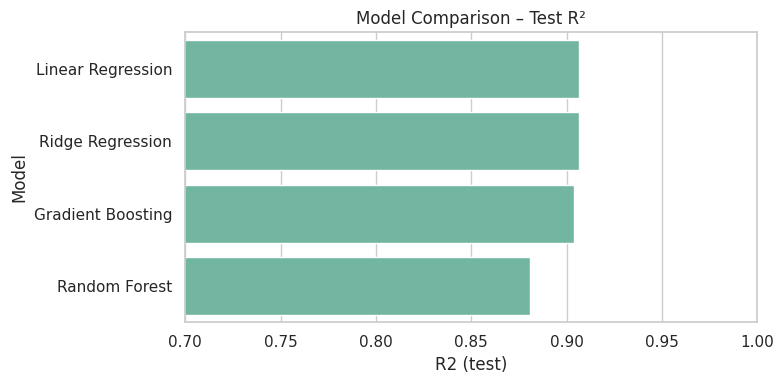

In [14]:
plt.figure(figsize=(8, 4))
sns.barplot(data=results_df, x="R2 (test)", y="Model")
plt.xlim(0.7, 1.0)
plt.title("Model Comparison – Test R²")
plt.tight_layout()
plt.savefig("figures/05_model_comparison.png", dpi=120)
plt.show()

## 8. Hyperparameter Tuning (Gradient Boosting)
Gradient Boosting has the most settings to tune, so we run a grid search with 5-fold cross-validation on the training set only.

In [15]:
gb_pipe = Pipeline([("prep", preprocessor),
                    ("model", GradientBoostingRegressor(random_state=RANDOM_STATE))])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3],
    "model__subsample": [0.8, 1.0],
}

grid = GridSearchCV(gb_pipe, param_grid, cv=5, scoring="r2", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV R2:", round(grid.best_score_, 4))

Best parameters: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 200, 'model__subsample': 0.8}
Best CV R2: 0.8471


## 9. Final Model Selection & Evaluation
We add the tuned Gradient Boosting model to the comparison and pick the model with the best test R².

In [16]:
fitted["Tuned Gradient Boosting"] = grid.best_estimator_
pred_tuned = grid.predict(X_test)
results.append({
    "Model": "Tuned Gradient Boosting",
    "R2 (test)": r2_score(y_test, pred_tuned),
    "MAE": mean_absolute_error(y_test, pred_tuned),
    "RMSE": np.sqrt(mean_squared_error(y_test, pred_tuned)),
    "CV R2 (mean)": grid.best_score_,
})
final_df = pd.DataFrame(results).sort_values("R2 (test)", ascending=False).reset_index(drop=True)
display(final_df.round(3))

best_name = final_df.loc[0, "Model"]
best_model = fitted[best_name]
pred = best_model.predict(X_test)

print("Selected model:", best_name)
print(f"R2   : {r2_score(y_test, pred):.4f}")
print(f"MAE  : ${mean_absolute_error(y_test, pred):,.2f}")
print(f"RMSE : ${np.sqrt(mean_squared_error(y_test, pred)):,.2f}")

,Model,R2 (test),MAE,RMSE,CV R2 (mean)
0,Linear Regression,0.907,2368.757,4142.307,0.847
1,Ridge Regression,0.906,2377.618,4146.447,0.847
2,Gradient Boosting,0.904,2439.986,4202.851,0.836
3,Tuned Gradient Boosting,0.902,2475.489,4235.449,0.847
4,Random Forest,0.881,2629.624,4676.597,0.820


Selected model: Linear Regression
R2   : 0.9066
MAE  : $2,368.76
RMSE : $4,142.31


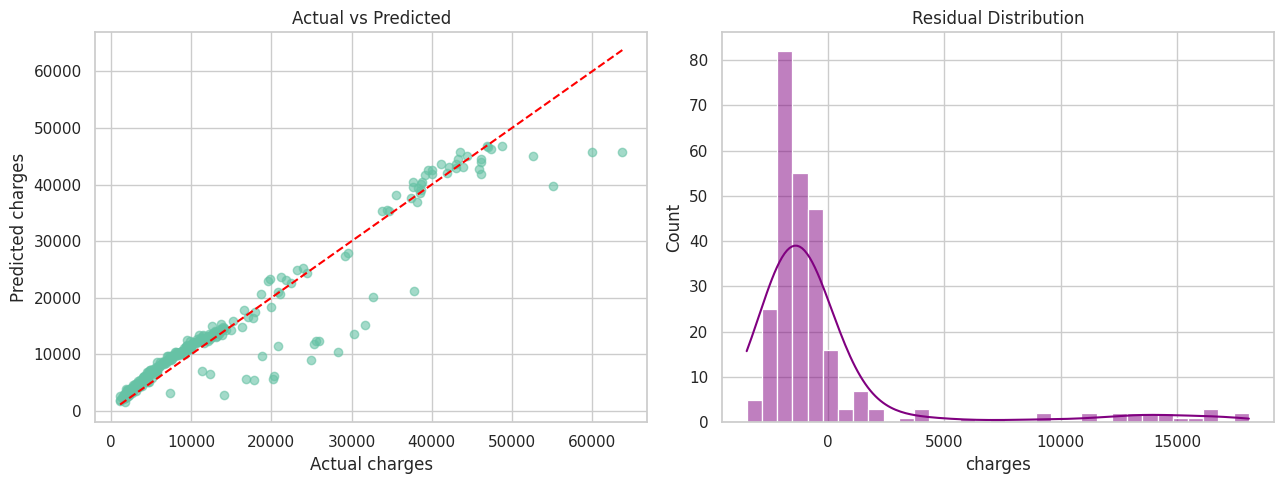

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, pred, alpha=0.6)
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, "r--")
ax[0].set_xlabel("Actual charges"); ax[0].set_ylabel("Predicted charges")
ax[0].set_title("Actual vs Predicted")

residuals = y_test - pred
sns.histplot(residuals, kde=True, ax=ax[1], color="purple")
ax[1].set_title("Residual Distribution")
plt.tight_layout()
plt.savefig("figures/06_actual_vs_predicted.png", dpi=120)
plt.show()

## 10. Feature Importance
Permutation importance shows how much the test score drops when a feature is shuffled.

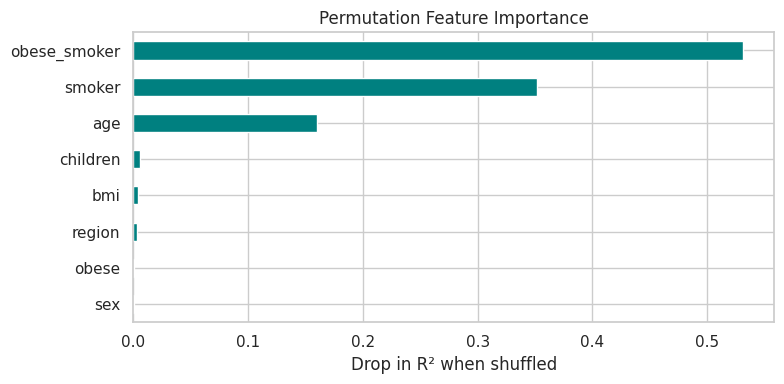

obese_smoker    0.5317
smoker          0.3516
age             0.1599
children        0.0053
bmi             0.0040
region          0.0027
obese           0.0006
sex             0.0005
dtype: float64

In [18]:
perm = permutation_importance(best_model, X_test, y_test, n_repeats=10,
                              random_state=RANDOM_STATE, scoring="r2")
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 4))
imp.plot(kind="barh", color="teal")
plt.title("Permutation Feature Importance")
plt.xlabel("Drop in R² when shuffled")
plt.tight_layout()
plt.savefig("figures/07_feature_importance.png", dpi=120)
plt.show()
imp.sort_values(ascending=False).round(4)

## 11. Save the Model & Make a Sample Prediction

In [19]:
joblib.dump(best_model, "medical_cost_model.pkl")

def predict_cost(age, sex, bmi, children, smoker, region):
    row = pd.DataFrame([{
        "age": age, "sex": sex, "bmi": bmi, "children": children,
        "smoker": smoker, "region": region,
        "obese": int(bmi >= 30),
        "obese_smoker": int(bmi >= 30 and smoker == "yes"),
    }])
    return best_model.predict(row)[0]

print("Smoker, 45 yrs, BMI 32 :", f"${predict_cost(45, 'male', 32, 2, 'yes', 'southeast'):,.0f}")
print("Non-smoker, 45 yrs, BMI 24:", f"${predict_cost(45, 'male', 24, 2, 'no', 'southeast'):,.0f}")

Smoker, 45 yrs, BMI 32 : $42,820
Non-smoker, 45 yrs, BMI 24: $9,818


## 12. Conclusion
- After adding the `obese` and `obese_smoker` features, even simple **Linear/Ridge Regression** reaches a test **R² of about 0.91** (MAE ≈ \$2,400), and the tuned Gradient Boosting model performs almost the same. The engineered features captured most of the non-linear behaviour, so the simpler and more interpretable model is selected.
- The **obese-smoker** flag and **smoking status** are the most important factors, followed by **age**. BMI alone adds little once the obese-smoker flag is present, because that flag already captures its effect.
- Sex, region and number of children contribute very little.
- **Limitations:** only 1,337 records and 6 inputs; no medical history is available; data is US-based and may not generalise to other countries.
- **Future work:** try XGBoost/LightGBM, model log(charges), and deploy as a Streamlit web app.